# 회귀 모델과 교차 검증

합성 데이터에 직선·평면·곡선 모델을 맞추고, 모델 복잡도에 따른 학습 오차와 검증 오차 비교.

실제 신체 측정 데이터가 아닌 수식으로 생성한 예제 데이터 사용. 커널 초기화 후 위에서부터 순서대로 실행.

In [1]:
# 기본 설정
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize

# 가독성
np.set_printoptions(precision=3, suppress=True)

## 2. 나이를 통한 키 예측

1차원 입력 데이터 생성, 입력 `x` 나이를 통한 정답 `t` 키 예측

X_age =
 [15.43 23.01  5.   12.56  8.67  7.31  9.66 13.64 14.92 18.47 15.48 22.13
 10.11 26.95  5.68 21.76]
T_height =
 [170.91 160.68 129.   159.7  155.46 140.56 153.65 159.43 164.7  169.65
 160.71 173.29 159.31 171.52 138.96 165.87]


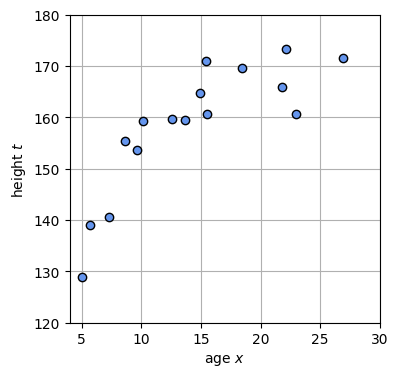

In [2]:
def make_age_height_data(seed=1):
    np.random.seed(seed=seed)
    x_min = 4
    x_max = 30
    x_n = 16
    x_age = 5 + 25 * np.random.rand(x_n)
    prm_c = [170, 108, 0.2]
    t_height = prm_c[0] - prm_c[1] * np.exp(-prm_c[2] * x_age) + 4 * np.random.randn(x_n)
    return x_age, t_height, x_min, x_max, x_n

X_age, T_height, X_min, X_max, X_n = make_age_height_data(seed=1)

X = X_age
T = T_height

print('X_age =\n', np.round(X_age, 2))
print('T_height =\n', np.round(T_height, 2))

plt.figure(figsize=(4, 4))
plt.plot(X, T, marker='o', linestyle='None', color='cornflowerblue', markeredgecolor='black')
plt.xlim(X_min, X_max)
plt.ylim(120, 180)
plt.xlabel('age $x$')
plt.ylabel('height $t$')
plt.grid(True)
plt.show()

## 3. 제곱 오차 함수

best w0 = 1.7676767676767682
best w1 = 132.62626262626262
minimum MSE = 50.87096405855861


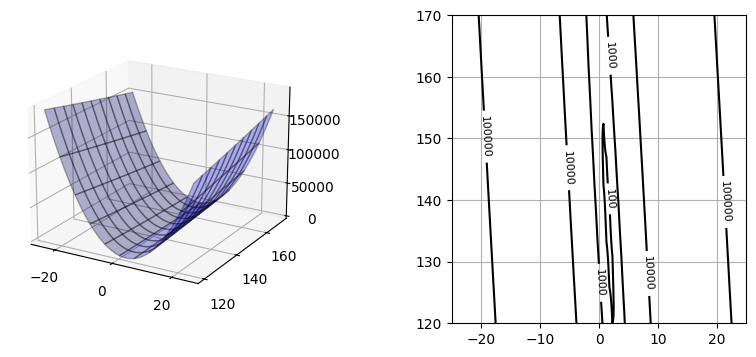

In [3]:
from mpl_toolkits.mplot3d import Axes3D

# 평균 제곱 오차 함수
def mse_line(x, t, w):
    y = w[0] * x + w[1]
    mse = np.mean((y - t) ** 2)
    return mse
    
# 계산
xn = 100 # 등고선 표시 해상도
w0_range = [-25, 25]
w1_range = [120, 170]
x0 = np.linspace(w0_range[0], w0_range[1], xn)
x1 = np.linspace(w1_range[0], w1_range[1], xn)
xx0, xx1 = np.meshgrid(x0, x1)
J = np.zeros((len(x0), len(x1)))

for i0 in range(xn):
    for i1 in range(xn):
        J[i1, i0] = mse_line(X, T, (x0[i0], x1[i1]))


min_index = np.unravel_index(np.argmin(J), J.shape)

best_w0 = x0[min_index[1]]
best_w1 = x1[min_index[0]]
best_mse = J[min_index]
print("best w0 =", best_w0)
print("best w1 =", best_w1)
print("minimum MSE =", best_mse)

# 표시
plt.figure(figsize=(9.5, 4))
plt.subplots_adjust(wspace=0.5)

ax = plt.subplot(1, 2, 1, projection='3d')
ax.plot_surface(xx0, xx1, J, rstride=10, cstride=10, alpha=0.3, 
                color='blue', edgecolor='black')
ax.set_xticks([-20, 0, 20])
ax.set_yticks([120, 140, 160])
ax.view_init(20, -60)

plt.subplot(1,2,2)
cont = plt.contour(xx0, xx1, J, 30, colors='black', 
                   levels=[100, 1000, 10000, 100000])
cont.clabel(fmt='%1.0f', fontsize=8)
plt.grid(True)
plt.show()

## 4. 경사하강법

In [4]:
# 직선 모델의 평균제곱오차 기울기
def dmse_line(x, t, w):
    y = w[0] * x + w[1]
    d_w0 = 2 * np.mean((y - t) * x)
    d_w1 = 2 * np.mean(y - t)
    return np.array([d_w0, d_w1])

# 경사하강법으로 w0, w1 찾기
def fit_line_num(x, t):
    w_init = [10.0, 165.0]  # 매개변수(w_0, w_1) 초기화

    alpha = 0.001      # 학습률
    i_max = 100000     # 종료 조건 1: 반복의 최대 횟수
    eps = 0.1          # 종료 조건 2: 기울기의 절댓값의 최소값

    # 반복 때마다 업데이트되는 매개변수 값 저장
    w_i = np.zeros([i_max, 2])
    w_i[0, :] = w_init

    for i in range(1, i_max):
        dmse = dmse_line(x, t, w_i[i - 1])

        w_i[i, 0] = w_i[i - 1, 0] - alpha * dmse[0] # 각 값의 진행방향 학습률에 곱해 조정
        w_i[i, 1] = w_i[i - 1, 1] - alpha * dmse[1]

        if max(np.absolute(dmse)) < eps:
            break

    w0 = w_i[i, 0]
    w1 = w_i[i, 1]
    w_i_hist = w_i[:i, :]

    return w0, w1, dmse, w_i_hist


# 경사하강법으로 데이터 생성 /매개변수구하기
w0, w1, dmse, W_history = fit_line_num(X, T)

print("w0 =", np.round(w0, 3)) #직선 기울기
print("w1 =", np.round(w1, 3)) #직선 절편
print("dmse =", np.round(dmse, 3)) # 마지막 기울기 0에 가까우면 학습완료 
print("MSE =", np.round(mse_line(X, T, [w0, w1]), 3)) #최종 오차



w0 = 1.54
w1 = 136.176
dmse = [-0.006  0.1  ]
MSE = 49.027


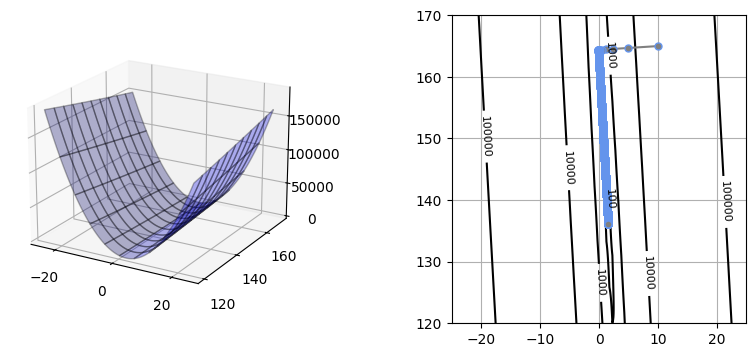

In [5]:
xn = 100 # 등고선 표시 해상도
w0_range = [-25, 25]
w1_range = [120, 170]
x0 = np.linspace(w0_range[0], w0_range[1], xn)
x1 = np.linspace(w1_range[0], w1_range[1], xn)
xx0, xx1 = np.meshgrid(x0, x1)
J = np.zeros((len(x0), len(x1)))

for i0 in range(xn):
    for i1 in range(xn):
        J[i1, i0] = mse_line(X, T, (x0[i0], x1[i1]))
        
# 표시
plt.figure(figsize=(9.5, 4))
plt.subplots_adjust(wspace=0.5)

ax = plt.subplot(1, 2, 1, projection='3d')
ax.plot_surface(xx0, xx1, J, rstride=10, cstride=10, alpha=0.3, 
                color='blue', edgecolor='black')
ax.set_xticks([-20, 0, 20])
ax.set_yticks([120, 140, 160])
ax.view_init(20, -60)

plt.subplot(1,2,2)
cont = plt.contour(xx0, xx1, J, 30, colors='black', 
                   levels=[100, 1000, 10000, 100000])
cont.clabel(fmt='%1.0f', fontsize=8)
plt.grid(True)

plt.plot(W_history[:, 0], W_history[:, 1], '.-', color='gray', markersize=10, markeredgecolor='cornflowerblue')
plt.show()

## 5. 모델 평가

w0=1.540, w1=136.176
mse=49.027 cm^2
SD=7.002 cm


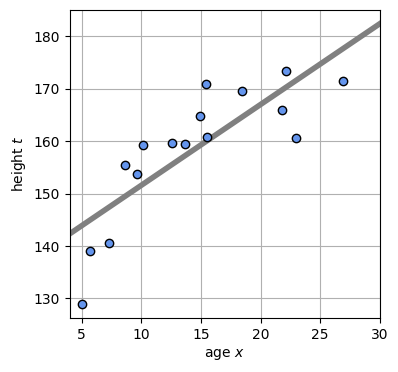

In [6]:
# 경사하강법으로 구한 매개변수를 적용한 모델 평가

W = np.array([w0, w1])
mse = mse_line(X, T, W)

print("w0={:.3f}, w1={:.3f}".format(w0, w1)) # 매개변수 출력
print("mse={:.3f} cm^2".format(mse)) # 현재 모델의 mse 출력
print("SD={:.3f} cm".format(np.sqrt(mse))) # 현재 모델의 sd 출력 표준편처 (ROOT MEAN SQURED ERROR)


def show_line(w):
    xb = np.linspace(X_min, X_max, 100)
    y = w[0] * xb + w[1]
    plt.plot(xb, y, color=(.5, .5, .5), linewidth=4)


plt.figure(figsize=(4, 4))

# 학습된 매개변수로 만들어진 직선 plot
show_line(W)

# 학습에 사용된 데이터의 분포 plot
plt.plot(
    X, T,
    marker='o',
    linestyle='None',
    color='cornflowerblue',
    markeredgecolor='black'
)

plt.xlim(X_min, X_max)
plt.xlabel('age $x$')
plt.ylabel('height $t$')
plt.grid(True)
plt.show()


## 6. 2차원 입력 면 모델

2차원 입력 데이터 생성,`x0` 나이, `x1` 몸무게를 통해 , `t` 키 예측

X0=
 [15.43 23.01  5.   12.56  8.67  7.31  9.66 13.64 14.92 18.47 15.48 22.13
 10.11 26.95  5.68 21.76]
X1=
 [70.43 58.15 37.22 56.51 57.32 40.84 57.79 56.94 63.03 65.69 62.33 64.95
 57.73 66.89 46.68 61.08]
T=
 [170.91 160.68 129.   159.7  155.46 140.56 153.65 159.43 164.7  169.65
 160.71 173.29 159.31 171.52 138.96 165.87]


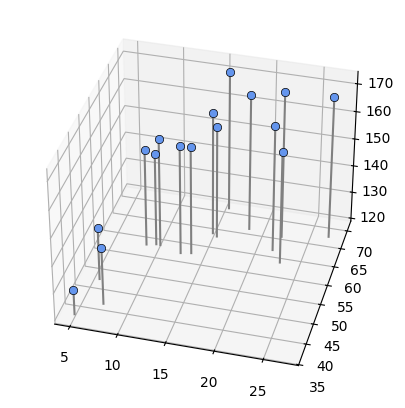

In [7]:
# 2차원 입력 데이터 생성
X0 = X
X0_min = 5
X0_max = 30

np.random.seed(seed=1)
X1 = 23 * (T / 100) ** 2 + 2 * np.random.randn(X_n)
X1_min = 40
X1_max = 75

print("X0=\n", np.round(X0, 2))
print("X1=\n", np.round(X1, 2))
print("T=\n", np.round(T, 2))

# 2차원 입력 데이터 표시

def show_data2(ax, x0, x1, t):
    for i in range(len(x0)):
        ax.plot(
            [x0[i], x0[i]],
            [x1[i], x1[i]],
            [120, t[i]],
            color='gray'
        )

    ax.plot(
        x0, x1, t,
        'o',
        color='cornflowerblue',
        markeredgecolor='black',
        markersize=6,
        markeredgewidth=0.5
    )

    ax.view_init(elev=35, azim=-75)

plt.figure(figsize=(6, 5))
ax = plt.subplot(1, 1, 1, projection='3d')
show_data2(ax, X0, X1, T)
plt.show()


## 7. 특징 벡터가 2차원

MSE = 165.789, SD = 12.876cm


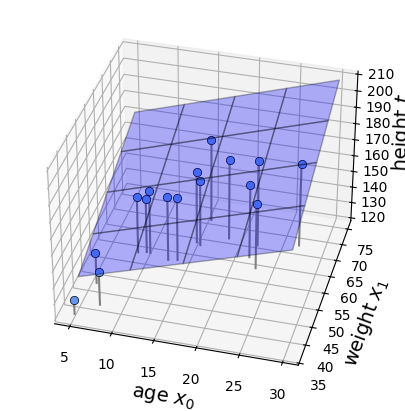

In [8]:
# 면의 MSE
def mse_plane(x0, x1, t, w):
    y = w[0] * x0 + w[1] * x1 + w[2]
    mse = np.mean((y - t) ** 2)
    return mse
# w_0=1.5, w_1=1.0, w_2=90 일 때 MSE
W = [1.5, 1, 90]
mse = mse_plane(X0, X1, T, W)

print("MSE = {:.3f}, SD = {:.3f}cm".format(mse, np.sqrt(mse)))
def show_plane(ax, w):
    px0 = np.linspace(X0_min, X0_max, 5)
    px1 = np.linspace(X1_min, X1_max, 5)
    px0, px1 = np.meshgrid(px0, px1)
    y = w[0] * px0 + w[1] * px1 + w[2]
    ax. plot_surface(px0, px1, y, rstride = 1, cstride = 1,
                     alpha = 0.3, color = 'blue', edgecolor = 'black')

plt.figure(figsize = (6, 5))
ax = plt.subplot(1, 1, 1, projection = '3d')
show_plane(ax, W)
show_data2(ax, X0, X1, T) 
ax.set_xlabel('age $x_0$', fontsize = 14)
ax.set_ylabel( 'weight $x_1$', fontsize = 14)
ax.set_zlabel('height $t$', fontsize = 14)

plt.show()

### 해석에 의한 평면 모델의 적합

MSE =  6.480, SD =  2.546cm


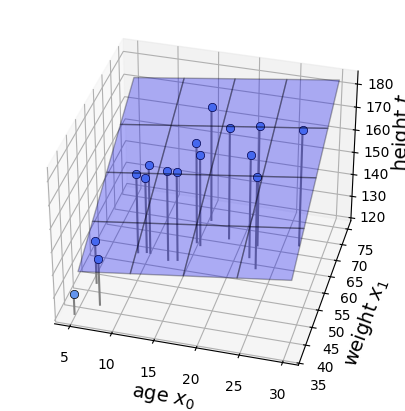

In [9]:
# 해석해
def fit_plane(x0, x1, t):
    c_tx0 = np.mean(t * x0) - np.mean(t) * np.mean(x0) # cov(t, x_0)
    c_tx1 = np.mean(t * x1) - np.mean(t) * np.mean(x1) # cov(t, x_1)
    c_x0x1 = np.mean(x0 * x1) - np.mean(x0) * np.mean(x1) # cov(x_0, x_1)
    v_x0 = np.var(x0) # var(x_0)
    v_x1 = np.var(x1) # var(x_1)
    w0 = (c_tx1 * c_x0x1 - v_x1 * c_tx0) / (c_x0x1 ** 2 - v_x0 * v_x1)
    w1 = (c_tx0 * c_x0x1 - v_x0 * c_tx1) / (c_x0x1 ** 2 - v_x0 * v_x1)
    w2 = -w0 * np.mean(x0) - w1 * np.mean(x1) + np.mean(t)
    return np.array([w0, w1, w2])


plt.figure(figsize = (6, 5))
ax = plt.subplot(1, 1, 1, projection = '3d')
W = fit_plane(X0, X1, T)
show_plane(ax, W)
show_data2(ax, X0, X1, T)
ax.set_xlabel('age $x_0$', fontsize = 14)
ax.set_ylabel('weight $x_1$', fontsize = 14)
ax.set_zlabel('height $t$', fontsize = 14)
mse = mse_plane(X0, X1, T, W)
print("MSE = {0: .3f}, SD = {1: .3f}cm" .format(mse, np.sqrt(mse)))
plt.show()

## 8. 선형 기저 함수 모델

가우스 기저 함수와 교차 검증의 데이터 1차원 입력 `x` 정답 `t`

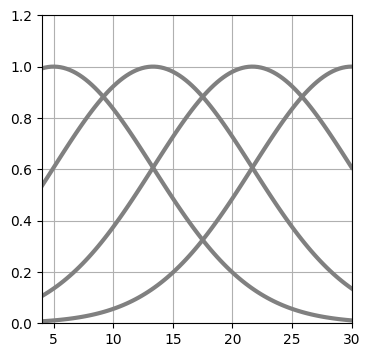

In [10]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# 미리선언한 변수 참조
X = X_age
X_min = X_min
X_max = X_max
X_n = X_n
T = T_height
# 기저함수로 가우스 함수 정의
def gauss(x, mu, s):
    return np.exp(-(x - mu) ** 2 / (2 * s ** 2))
M = 4

plt.figure(figsize=(4, 4))

mu = np.linspace(5, 30, M)  # 5 ~ 30 까지 균일하게 4등분
s = mu[1] - mu[0]           # 인접한 가우스 함수 간 중심 사이의 거리
xb = np.linspace(X_min, X_max, 100)

for j in range(M):
    y = gauss(xb, mu[j], s)
    plt.plot(xb, y, color='gray', linewidth=3)

plt.grid(True)
plt.xlim(X_min, X_max)
plt.ylim(0, 1.2)
plt.show()

In [11]:
# 기초함수선언
X = X_age
T = T_height
X_min = 4
X_max = 30
X_n = len(X)

# 훈련용 테스트용 분리
idx = np.arange(X_n)
X_train, T_train = X[idx % 4 != 0], T[idx % 4 != 0]
X_test, T_test = X[idx % 4 == 0], T[idx % 4 == 0]

# 가우스 기저 함수 생성
def _gauss_basis(x, m):
    x = np.asarray(x)
    mu = np.linspace(X_min, X_max, m)
    s = (mu[1] - mu[0]) if m > 1 else (X_max - X_min)
    return np.exp(-((x[:, None] - mu[None, :]) ** 2) / (2 * s ** 2))

# 예측값 생성
def gauss_func(w, x):
    x = np.asarray(x)
    m = len(w) - 1
    mu = np.linspace(5, 30, m)
    s = mu[1] - mu[0]

    y = np.zeros_like(x, dtype=float)

    for j in range(m):
        y = y + w[j] * gauss(x, mu[j], s)

    y = y + w[m]
    return y

# 가우스 함수를 기저함수로 하는 선형 기저 모델의 MSE 해석해
def fit_gauss_func(x, t, m):
    mu = np.linspace(5, 30, m)
    s = mu[1] - mu[0]
    n = x.shape[0]
    phi = np.ones((n, m + 1))

    for j in range(m):
        phi[:, j] = gauss(x, mu[j], s)

    phi_T = np.transpose(phi)

    b = np.linalg.inv(phi_T.dot(phi))
    c = b.dot(phi_T)
    w = c.dot(t)

    return w


# 평균재곱오차
def mse_gauss_func(x, t, w):
    y = gauss_func(w, x)
    return np.mean((y - t) ** 2)

# 나이를 통한 성장감소 모델
def model_A(x, w):
    return w[0] - w[1] * np.exp(-w[2] * x)

# 성장감소 모델 평균제곱오차
def mse_model_A(w, x, t):
    y = model_A(x, w)
    return np.mean((y - t) ** 2)

# 
def fit_model_A(w_init, x, t):
    res = minimize(lambda w: mse_model_A(w, x, t), np.asarray(w_init), method='Nelder-Mead')
    return res.x


## 선형 기저 함수 모델

W= [29.4 75.7  2.9 98.3 54.9]
SD= 3.98 cm


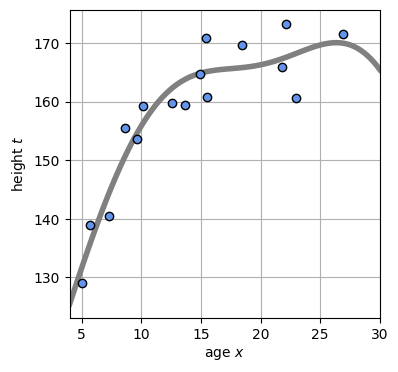

In [12]:
# 가우스 기저 함수 표시
def show_gauss_func(w):
    xb = np.linspace(X_min, X_max, 100)
    y = gauss_func(w, xb)
    plt.plot(xb, y, c=[.5, .5, .5], lw=4)
    

plt.figure(figsize=(4, 4))
M = 4
W = fit_gauss_func(X, T, M)
show_gauss_func(W)
plt.plot(X, T, marker='o', linestyle='None', color='cornflowerblue', markeredgecolor='black')
plt.xlim(X_min, X_max)
plt.xlabel("age $x$")
plt.ylabel("height $t$")
plt.grid(True)
mse = mse_gauss_func(X, T, W)
print("W=", np.round(W, 1))
print("SD={0: .2f} cm".format(np.sqrt(mse)))
plt.show()

### 과적합

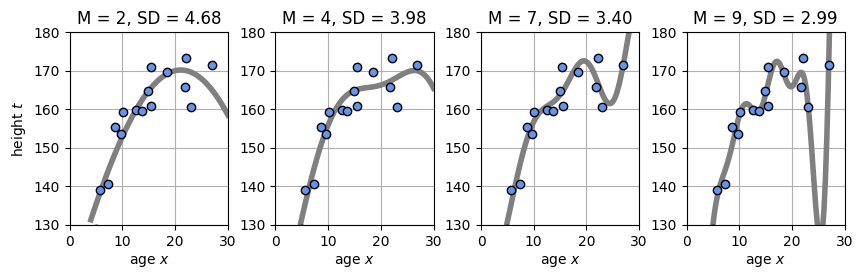

In [13]:
# 기저함수의 수인 M 값을 2, 4, 7, 9 로 조정하여 출력한다
M = [2, 4, 7, 9]

plt.figure(figsize=(10, 2.5))
plt.subplots_adjust(wspace=0.3)

for i in range(len(M)):
    plt.subplot(1, len(M), i + 1)
    W = fit_gauss_func(X, T, M[i])
    show_gauss_func(W)

    plt.plot(
        X, T,
        marker='o',
        linestyle='None',
        color='cornflowerblue',
        markeredgecolor='black'
    )

    plt.xlim(0, X_max)
    plt.ylim(130, 180)
    plt.xlabel('age $x$')

    if i == 0:
        plt.ylabel('height $t$')

    plt.grid(True)

    mse = mse_gauss_func(X, T, W)
    plt.title("M = {0:d}, SD = {1:.2f}".format(M[i], np.sqrt(mse)))

plt.show()


### 기저함수 수에 따른 오차측정

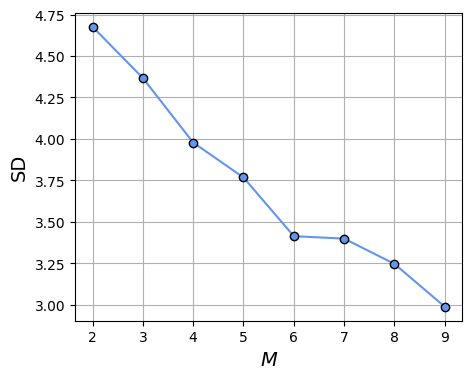

In [14]:
plt.figure(figsize = (5, 4))
M = range(2, 10)
mse2 = np.zeros(len(M))

for i in range(len(M)):
    W = fit_gauss_func(X, T, M[i])
    mse2[i] = np.sqrt(mse_gauss_func(X, T, W))

plt.plot(M, mse2, marker = 'o', color = 'cornflowerblue', markeredgecolor = 'black')
plt.xlabel('$M$', fontsize = 14)
plt.ylabel('SD', fontsize = 14)
plt.grid(True)
plt.show()

### HOLDOUT 검증

In [15]:
# Holdout 검증: 훈련 데이터로 사용하지 않은 데이터를 테스트 데이터로 사용하는 경우
# 훈련 데이터: 전체 데이터의 3/4, 테스트 데이터 1/4

# 훈련 데이터와 테스트 데이터 생성
X_test = X[:int(X_n / 4)]
T_test = T[:int(X_n / 4)]

X_train = X[int(X_n / 4):]
T_train = T[int(X_n / 4):]

print('X_test: ' + str(X_test.shape))
print('T_test: ' + str(T_test.shape))
print('X_train: ' + str(X_train.shape))
print('T_train: ' + str(T_train.shape))
plt.show()

X_test: (4,)
T_test: (4,)
X_train: (12,)
T_train: (12,)


### HLODOUT 검증을 통한 학습 결과비교

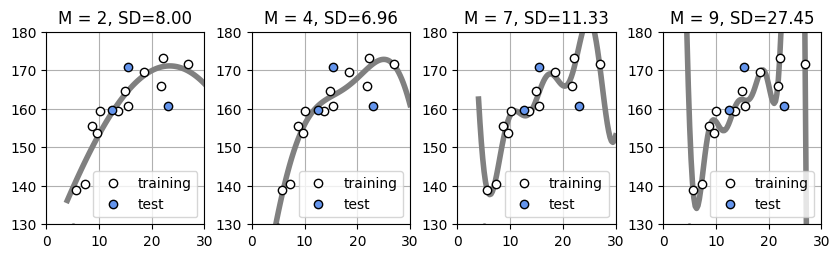

제일 낮은 SD M = 4 SD = 6.962406586172508
제일 높은 SD M = 9 SD = 27.44611892529663


In [16]:
plt.figure(figsize = (10, 2.5))

plt.subplots_adjust(wspace = 0.3)
M = [2, 4, 7, 9]
sd_list = []

for i in range(len(M)):
    plt.subplot(1, len(M), i + 1)
    W = fit_gauss_func(X_train, T_train, M[i])
    show_gauss_func(W)
    plt.plot(X_train, T_train, marker = 'o', linestyle = 'None', color = 'white', markeredgecolor = 'black', label = 'training')
    plt.plot(X_test, T_test, marker = 'o', linestyle = 'None', color = 'cornflowerblue', markeredgecolor = 'black', label = 'test')
    plt.legend(loc = 'lower right', fontsize = 10, numpoints = 1)
    plt.xlim(0, X_max)
    plt.ylim(130, 180)
    plt.grid(True)
    mse = mse_gauss_func(X_test, T_test, W)
    sd = np.sqrt(mse)
    sd_list.append(sd)
    plt.title("M = {0:d}, SD={1:.2f}" .format(M[i], np.sqrt(mse)))
plt.show()


sd_array = np.array(sd_list)
min_index = np.argmin(sd_array)
max_index = np.argmax(sd_array)

print("제일 낮은 SD M =", M[min_index], "SD =", sd_array[min_index])
print("제일 높은 SD M =", M[max_index] , "SD =", sd_array[max_index])

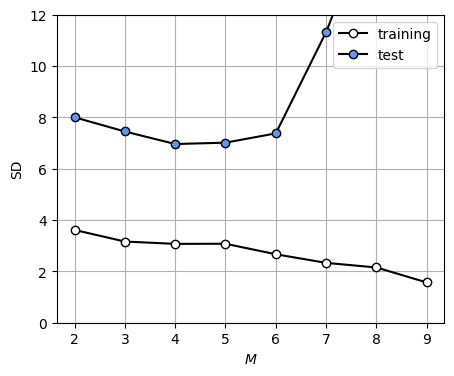

In [17]:
plt.figure(figsize = (5, 4))
M = range(2, 10)
mse_train = np.zeros(len(M))
mse_test = np.zeros(len(M))

for i in range(len(M)):
    W = fit_gauss_func(X_train, T_train, M[i])
    mse_train[i] = np.sqrt(mse_gauss_func(X_train, T_train, W))
    mse_test[i] = np.sqrt(mse_gauss_func(X_test, T_test, W))
    
plt.plot(M, mse_train, marker = 'o', linestyle = '-', markerfacecolor = 'white', markeredgecolor = 'black', color = 'black', label = 'training')
plt.plot(M, mse_test, marker = 'o', linestyle = '-', markerfacecolor = 'cornflowerblue', markeredgecolor = 'black', color = 'black', label = 'test')
plt.legend(loc = 'upper right', fontsize = 10)
plt.ylim(0, 12)
plt.xlabel('$M$')
plt.ylabel('SD')
plt.grid(True)
plt.show()

### K겹 교차 검증

In [18]:
def kfold_gauss_func(x, t, m, k):
    n = x.shape[0]
    mse_train = np.zeros(k)
    mse_test = np.zeros(k)
    
    for i in range(0, k):
        x_train = x[np.fmod(range(n), k) != i]
        t_train = t[np.fmod(range(n), k) != i]  
        x_test = x[np.fmod(range(n), k) == i]
        t_test = t[np.fmod(range(n), k) == i] 
        wm = fit_gauss_func(x_train, t_train, m)
        mse_train[i] = mse_gauss_func(x_train, t_train, wm)
        mse_test[i] = mse_gauss_func(x_test, t_test, wm)
        
    return mse_train, mse_test

M = 4
K = 4

kfold_gauss_func(X, T, M, K)

# 첫번째 행: 각각의 분할에서 훈련 데이터의 평균제곱오차
# 두번째 행: 각각의 분할에서 테스트 데이터의 평균제곱오차


(array([12.879,  9.818, 17.262, 12.923]),
 array([ 39.653, 734.708,  18.309,  47.525]))

### LOOCV

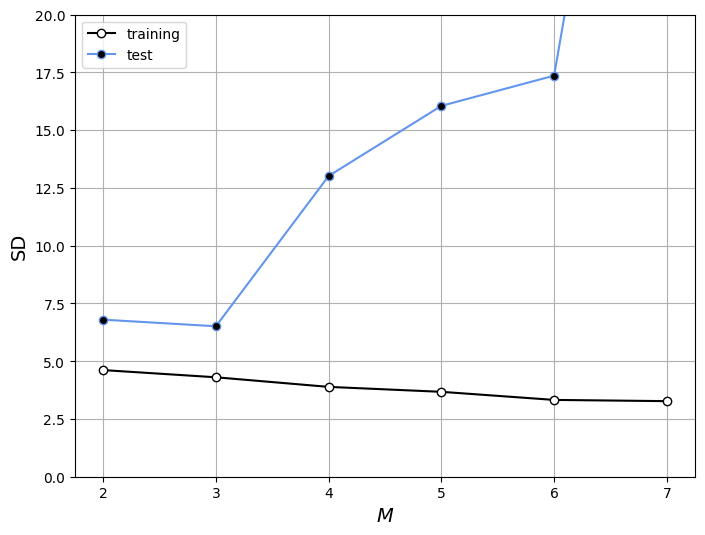

M > 3 에서 과적합 발생
M = 3 일 때 최적


In [19]:
#분할 수를 최대의 16(LOOCV)으로 하고 2에서 7까지의 M으로 오차의 평균을 계산하고 그린다 
M = range(2, 8)
K = 16
Cv_Gauss_train = np.zeros((K, len(M)))
Cv_Gauss_test = np.zeros((K, len(M)))

for i in range(0, len(M)):
    Cv_Gauss_train[:, i], Cv_Gauss_test[:, i] = kfold_gauss_func(X, T, M[i], K)
    mean_Gauss_train = np.sqrt(np.mean(Cv_Gauss_train, axis = 0))
    mean_Gauss_test = np.sqrt(np.mean(Cv_Gauss_test, axis= 0))
    
    
plt.figure(figsize = (8, 6))
plt.plot(M, mean_Gauss_train, marker = 'o', linestyle = '-', color = 'k', markerfacecolor = 'w', label = 'training')
plt.plot(M, mean_Gauss_test, marker = 'o', linestyle = '-', color = 'cornflowerblue', markerfacecolor = 'black', label = 'test')
plt.legend(loc = 'upper left', fontsize = 10)
plt.xlabel('$M$', fontsize = 14)
plt.ylabel('SD', fontsize = 14)
plt.ylim(0, 20)
plt.grid(True)
plt.show()

# 선형 기저 함수 모델의 LOOCV
# 훈련 데이터에 대한 오차(SD)는 M이 증가하면 줄어든다
# M>3 에서 overfitting 시작 되고 있다. 테스트 데이터에 대한 오차(SD)는 M = 3일 때 최소치

best_index = np.argmin(mean_Gauss_test)
best_M = list(M)[best_index]

print("M > {} 에서 과적합 발생".format(best_M))
print("M = {} 일 때 최적".format(best_M))

### 최적의 수로 선형기저함수 피팅

오차 SD= 4.37 cm


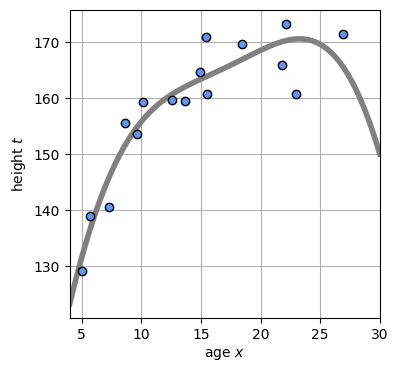

In [20]:
M = 3
plt.figure(figsize = (4, 4))
W = fit_gauss_func(X, T, M)
show_gauss_func(W)
plt.plot(X, T, marker = 'o', linestyle = 'none', color = 'cornflowerblue', markeredgecolor = 'black')
plt.xlim([X_min, X_max])
plt.xlabel('age $x$')
plt.ylabel('height $t$')
plt.grid(True)
mse = mse_gauss_func(X, T, W)
print("오차 SD= {0:.2f} cm" .format(np.sqrt(mse)))
plt.show()

### 모델 A생성

w0 = 169.040, w1 = 113.661, w2 = 0.217
SD = 3.86 cm


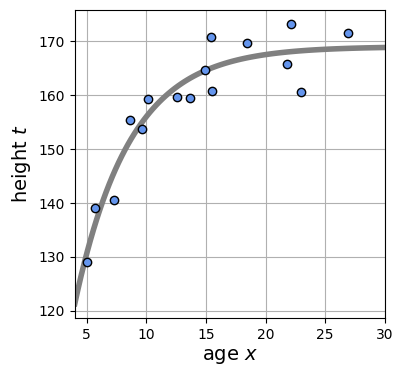

In [21]:
# 모델 A
def model_A(x, w):
    y = w[0] - w[1] * np.exp(-w[2] * x)
    return y


# 모델 A의 MSE
def mse_model_A(w, x, t):
    y = model_A(x, w)
    mse = np.mean((y - t) ** 2)
    return mse


# 모델 A의 경사하강법
from scipy.optimize import minimize

def fit_model_A(w_init, x, t):
    res1 = minimize(mse_model_A, w_init, args=(x, t), method='powell')
    return res1.x
# 모델 A plot
def show_model_A(w):
    xb = np.linspace(X_min, X_max, 100)
    y = model_A(xb, w)
    plt.plot(xb, y, c=[.5, .5, .5], lw=4)

plt.figure(figsize = (4, 4))
W_init = [100, 0, 0]
W = fit_model_A(W_init, X, T)
print("w0 = {0:.3f}, w1 = {1:.3f}, w2 = {2:.3f}" .format(W[0], W[1], W[2]))
show_model_A(W)
plt.plot(X, T, marker='o', linestyle='None', color = 'cornflowerblue', markeredgecolor = 'black')
plt.xlim(X_min, X_max)
plt.xlabel('age $x$', fontsize = 14)
plt.ylabel('height $t$', fontsize = 14)
plt.grid(True)
mse = mse_model_A(W, X, T)
print("SD = {0:.2f} cm" .format(np.sqrt(mse)))
plt.show()

### 교차 검증을 통한 모델 A와 선형 기저 함수 모델의 성능 비교

[169.578 111.108   0.209]
Gauss(M=3): SD= 6.51 cm
Model A: SD= 4.72 cm


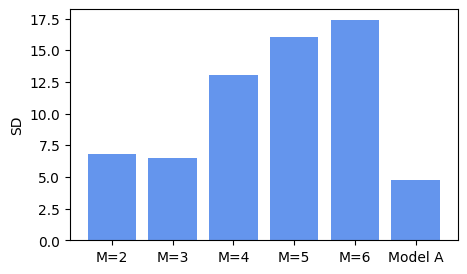

In [22]:
def kfold_model_A(x, t, k):
    n = len(x)
    mse_train = np.zeros(k)
    mse_test = np.zeros(k)
    
    for i in range(0, k):
        x_train = x[np.fmod(range(n), k) != i]
        t_train = t[np.fmod(range(n), k) != i]  
        x_test = x[np.fmod(range(n), k) == i]
        t_test = t[np.fmod(range(n), k) == i] 
        wm = fit_model_A(np.array([169, 113, 0.2]), x_train, t_train)
        mse_train[i]  = mse_model_A(wm, x_train, t_train)
        mse_test[i]  = mse_model_A(wm, x_test, t_test)
    
    print(wm)
    return mse_train, mse_test


K = 16 # LOOCV  를 위하여 K=N
Cv_A_train, Cv_A_test = kfold_model_A(X, T, K)
mean_A_test = np.sqrt(np.mean(Cv_A_test))
print("Gauss(M=3): SD={0: .2f} cm" .format(mean_Gauss_test[1]))
print("Model A: SD={0: .2f} cm" .format(mean_A_test))
SD = np.append(mean_Gauss_test[0:5], mean_A_test)
M = range(6)
label = ["M=2", "M=3", "M=4", "M=5", "M=6", "Model A" ]
plt.figure(figsize = (5, 3))
plt.bar(M, SD, tick_label = label, align = "center", facecolor = "cornflowerblue")
plt.ylabel('SD')
plt.show()